# chip_02 — five Xmons on one feedline, resonator-length sweep (legacy QWri), on the Quantcore PDK

## 1 · What the chip is

**Source:** `components/python/chip_02_creator.py` (`create_chip(size)`, writes `chip_02_<size>.gds`):
chip_01_creator with five different resonator lengths (5050, 4850, 4660, 4330, 4000 µm, all with a 500 µm
neck), re-positioned Xmons and nine AVA junction test pads, Quantcore internal. Spec:
`docs/designs/legacy/chip_02.md`. This notebook builds **JS = 1.0** (the script default).

A 7.5 × 7.5 mm die: one 10/6 µm CPW feedline between two rounded connector pads; five λ/4 `Coupled
Resonator` meanders (300 µm coupler behind a 2 µm ground strip), three above and two below the feedline at a
1000 µm pitch, each ending on the claw of an `Xmon Cross`. Four Xmons have a single junction behind the
south arm; the centre one (`res_fixed`) has none. Nine `testPad_AVAQUS` test pads: one beside the lower-right
corner, eight along the edges.

| | the rebuild keeps (source-faithful) | the Quantcore PDK changes |
|---|---|---|
| resonators, Xmons | the five `Coupled Resonator`s and `Xmon Cross`es with the legacy parameters (`CoupledResonator`, `Xmon`), legacy x and rotation; each claw joined to its resonator's open end | — |
| feedline, pads | rounded "Connector Pad" geometry (`ConnectorPad`, fab drawing), 10/6 µm CPW (`CpwSegment`) | pads with their outer etch **`pad_edge` = 100 µm** from the die edge (legacy: 245 µm *outside* the 7.5 mm die): feedline 5950 → 5260 µm |
| junctions | the legacy junction (`junction_creator.py`, cell `JUNC`) is missing from the library | the PDK **`Quantcore Junction`** (trilayer), sized by the rule: the legacy nominal (AVA fingers 0.26 × 0.2 µm at JS 1.0) gets R_n 45 kΩ |
| test pads | nine `testPad_AVAQUS` pads (`JunctionTestPads`) at the legacy positions (eight reach into the 100 µm die margin) | valued on the PDK process, not resized or moved |
| cheese | — (the source has none) | the **PDK band** (3 rows of 5 µm squares, 20 µm gaps, around the 3/0 keep-outs; `cheese: "auto"`) |
| placement | everything relative to the feedline | the circuit **centred in the die** where it is more than 50 µm off (step 6) |
| frame | — | the PDK die frame (dicing L markers, alignment grids, device ID) instead of the legacy corner `Marker`s; the "JS=…" and digit labels are not drawn |

**Reproduced exactly** (XOR against the author's own PCells, run read-only through `tests/legacy_ref`, step 14):
the resonators, the Xmon crosses and claws, the test pads, and the pads + feedline at their PDK position. The
junction windows differ by design (the PDK cell draws its own CLEARER box).

### Changes after design review (2026-11-03)

- **#8 resonator tails ↔ Xmon claws — geometry corrected** (review note: "the resonator tail protrudes into the xmon claw;
  correct the geometry"). As drawn, R1 and R4 stopped 164 and 195 µm short of their claw tails (claw shorted to ground, resonator uncoupled); R2, R3 and R5 ran ≈ 215 µm past the claw tips, their gaps cutting through the claw. Now every resonator ends **without a gap cap** (`ground=False`, the legacy
  `Coupled Resonator`'s own "xmon connector" mode, as in the author's later chips 05 and 10a) and its Xmon is **snapped
  with the claw-tail tip onto that end** (`snap="claw_n", to="Ri.end"`): the claw is the λ/4's open end, galvanically.
  Each Xmon keeps its x and rotation and only moves along the tail axis (table after the layout cell; the gap
  between claw tip and tail end is 0). The line now also includes the claw's 50 µm tail stub.
- **#9 pads outside the die — repositioned.** At the legacy tips (∓2975, 0) the rounded pads ended 245 µm outside
  the 7.5 mm die (the chip was laid out for a smaller die / a 2 × 2 tiling in which neighbours' pads overlap). They
  now sit 345 µm further in (tips ∓2630, feedline 5950 → 5260 µm), so the rounded end lies on the design-area edge,
  100 µm inside the die: clear of the dicing lane and of the corner markers, and the feedline still spans all five
  couplers (x = −2150 … +2150). Fab pad geometry, as before.
- **#1 / PDK rebuild — junctions.** The qubits' junction was `Trilayer Junction` at its default fingers, a stand-in for the missing `junction_creator.py`. It is now the PDK
  **`Quantcore Junction`** cell (fingers on 2/0 + 4/0, spacer 50/0 with the 51–53/0 gradient, CLEARER box), sized by the
  PDK junction rule (Nb, Δ = 1.4 meV, I_c·R_n = πΔ/2e = 2.20 mV, R_n 40–50 kΩ, qubits 4–8 GHz): the legacy
  nominal junction (JS 1.0) gets R_n = 45 kΩ
  (L_J 6.73 nH; `junction_params={"lj_nH": …}`), other JS sizes R_n ∝ 1/area. The `testPad_AVAQUS` pads keep their
  legacy JS fingers, valued on the PDK process (R_n·A 13.5 kΩ·µm², assumed by the PDK): at JS 1.0 they read
  ≈ 260 kΩ, so they track the JS scale but no longer the qubit junction's size — resize them if they should (design
  decision). The earlier assumed J_c = 1 µA/µm² is gone. Values in section 4.
- **Claw-tail gap (#22):** the Xmon's claw tail is now cleared by its own `claw_tail_gap` (default: the chip CPW gap, 6 µm); `L.xmon` sets it to the legacy `cap_spacing` = 6 µm, as the legacy
  `Xmon Cross` draws it, matching the 10/6 µm resonators.
- **Not re-executed here** (verification policy for this pass): the saved JSON is rebuilt from the layout
  cell, the outputs are cleared; run the notebook to regenerate the tables and PNGs.

### PDK conformance pass (notebooks-legacy, 2026-11-10)

- **Pads:** the left pad is placed with `edge="auto"` (outer etch `get_pdk().frame.pad_edge` = 100 µm from
  the die edge, the PDK pad rule; 25 µm until 2026-11-10), the feedline snaps onto its port with the length
  the rule leaves on a symmetric chip, and the right pad snaps onto the feedline's far end. The rule puts the
  pads exactly where the design decision had moved them by hand (rounded end on the design-area edge, tips
  ∓2630 µm, feedline 5260 µm): the hard-coded `PAD_SHIFT = 345` is gone, the shift is now measured.
- **Centring:** `L.center_circuit` (labels excluded from the measure, moved with everything; each axis only
  if > 50 µm off).
- **Cheese:** the source has none, so the PDK band applies (`cheese: "auto"`), drawn by the build and kept by
  the fab export.
- **Junctions:** PDK trilayer cells sized by the rule (unchanged from the legacy fix).
- Educative layout: one step per stage (die → pads and feedline → resonators and Xmons → test pads and
  centring → DRC → LOM → FEM → iterate → export → snapshots).

## 2 · Setup and the Quantcore PDK

The helpers keep the cells short: `_common` (`C`) holds the netlist / LOM / FEM-export / snapshot helpers and
the PDK checks shared by every design notebook; `_legacy` (`L`) maps the legacy PCell parameters onto the
Quantcore cells, draws the legacy reference with the author's own legacy code (read-only), and holds the step
helpers of these notebooks. `LIVE` decides whether the design is pushed to a running KLayout (`QCC_LIVE=0`
for batch runs: nothing reaches KLayout).

In [2]:
%config InlineBackend.figure_formats = ["png"]
import os, sys
from pathlib import Path
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "pyproject.toml").exists())
os.chdir(ROOT)                                       # paths below are relative to the repo root
sys.path.insert(0, str(ROOT / "examples" / "designs"))
sys.path.insert(0, str(ROOT / "examples" / "designs" / "legacy"))
LIVE = os.environ.get("QCC_LIVE", "1") == "1"       # live KLayout by default; QCC_LIVE=0 for batch runs
import _common as C                                  # netlist / LOM / FEM-export / snapshot / PDK-check helpers
import _legacy as L                                  # legacy frame shift, parameter mapping, legacy reference, steps
from quantcore_circuits.layouts.others.test_pads import legacy_test_pad_params
from IPython.display import Image, Markdown, display
from quantcore_circuits.designer import Designer
from quantcore_circuits.pdk import get_pdk

ID, OUT = "chip_02", Path("examples/designs/legacy")

The PDK facts this rebuild uses, read from `get_pdk()` (nothing below is typed in by hand). The rules that
change a legacy chip are the **pad rule** (step 4), the **junction rule** (step 5), the **3/0 keep-out**
and the **cheese rule** (drawn by the build, step 13) and the centring of the content (step 6).

In [3]:
CHEESE_NOTE = 'PDK band (auto) — the source has no cheese of its own'
display(Markdown(L.pdk_facts_md(CHEESE_NOTE)))

| PDK item | value |
|---|---|
| PDK | `quantcore_nb_sapphire_v1` (version 3) |
| stack | sapphire, 650 µm, ε_r 10.25; Nb film (sheet metal in the FEM exports, 0.2 µm for the analytic CPW formulas) |
| CPW default | 10 µm centre, 6 µm gap, bends r = 100 µm |
| die frame | L-shaped dicing markers 25 µm wide (250 µm legs, 1000/0), 3 × 3 alignment grids (1001/0) in 500 µm corner squares, design area 100 µm inside the die edge, device ID optional (bottom centre, or beside the pads) |
| pad rule | bond pads / launchers: outer etch edge **100 µm** (the design-area margin) from the die edge, whatever the original did (`edge="auto"`, DRC design warning `pad_edge`) |
| junction rule | Nb/AlOx/Nb trilayer, Δ = 1.4 meV (I_c·R_n = πΔ/2e), R_n 40–50 kΩ (nominal 45), qubits 4–8 GHz; R_n·A 13500 Ω·µm² and C_J 50 fF/µm² assumed; cells `Quantcore Junction` / `Quantcore Squid` (DRC design warnings `pdk_rn`, `pdk_fq`: flagged, never retuned) |
| 3/0 keep-out | second-metal etch: routes + 10 µm, components' etch bbox + 24 µm, other 1/0 shapes + 9 µm (filled) |
| cheese rule | 3 rows of 5 µm squares, 20 µm gaps, in a band around the 3/0 keep-outs; **the original design's own cheese wins** (chip `cheese`: `"auto"` / `"pdk"` / `"original"`). This chip: PDK band (auto) — the source has no cheese of its own |

### The source's numbers

The tables below are the legacy script's numbers in its own (0, 0)-centred frame (µm); `L.place(x, y, rot,
mirror)` shifts them by (+3750, +3750) into the Designer frame (origin at the lower-left die corner) and turns
the legacy `Trans` code into degrees. `L.xmon`, `L.coupled_resonator`, `L.connector_pad` and `L.cpw_segment`
map the legacy PCell parameters (with the legacy defaults) onto the Quantcore cells. The junction rule is
declared here too (`L.nominal`, explained in step 5).

In [4]:
JS = 1.0                    # junction scale (create_chip(size); no caller in the library)
# `chip_02_creator.py`, legacy frame (µm)
FEED = dict(length=5950, lc_thickness=2, rc_thickness=2)                       # "Coplanar Waveguide"
PAD = dict(trace_width=10, pad_height=300, pad_width=275, conn_height=300)     # "Connector Pad" (round default)
RES = dict(clength=300, cgap=2, width=300, flip=False, ground=False)           # "Coupled Resonator";
#   ground=False: no end cap, the PCell's "xmon connector" end, joined to the claw tip (#8)
XMON = dict(handle=1, cap_spacing=6, da=3, thickness=30, spacing=18)           # "Xmon Cross"
#          x    y_res mirror neck cpw_len y_xmon rot junction   (y_xmon: legacy, see #8)
QUBITS = [(-2000,  26, True,  500, 5050,  2270, 2, True),
          (-1000, -26, False, 500, 4850, -2100, 0, True),
          (    0,  26, True,  500, 4660,  1910, 2, False),   # res_fixed: Xmon without junction
          ( 1000, -26, False, 500, 4330, -1990, 0, True),
          ( 2000,  26, True,  500, 4000,  1660, 2, True)]
#             x      y   rot mirror      testPad_AVAQUS ("TESTAVA")
TESTPADS = [(3000, -1500, 0, False),
            (-2500, 3250, 0, False), (2500, 3250, 0, False), (-2500, -3250, 0, True), (2500, -3250, 0, True),
            (-3250, 2500, 1, False), (-3250, -2500, 1, False), (3250, -2500, 3, False), (3250, 2500, 3, False)]
JJ_N = 1   # junction_creator.py (cell JUNC) is missing → the PDK "Quantcore Junction" cell, sized by the rule
JJ_FINGERS = TEST_PAD_FINGERS = (0.2 * JS + 0.06, 0.2 * JS)   # AVA test-pad fingers (assumed for the qubits too)
TEST_PAD = ("JunctionTestPads", legacy_test_pad_params("testPad_AVAQUS", JS))
LEGACY_TP = ("testPad_AVAQUS.py", "create_testPad", "TESTAVA", JS)
CUT_H = 18                  # legacy CLEARER box 30 × CUT_H µm at every junction
L.nominal(*JJ_FINGERS, label=f"JS {JS}: {JJ_FINGERS[0]:g} × {JJ_FINGERS[1]:g} µm")   # legacy nominal → R_n 45 kΩ

2340.0

## 3 · The die and the frame

`Designer(ID, box=...)` starts an empty 7.5 × 7.5 mm die (the PDK standard die). The PDK frame is drawn on
every build: four L-shaped dicing markers (1000/0), the 3 × 3 alignment grids in the corners (1001/0), the
chip boundary (100/0) and the device ID (`name_chip`) at the bottom centre. The chip parameter `cheese` is
left at `"auto"`: the source has no cheese, so the build draws the PDK band (visible from step 5 on).

(0.0, 0.0, 7500.0, 7500.0) quantcore_nb_sapphire_v1


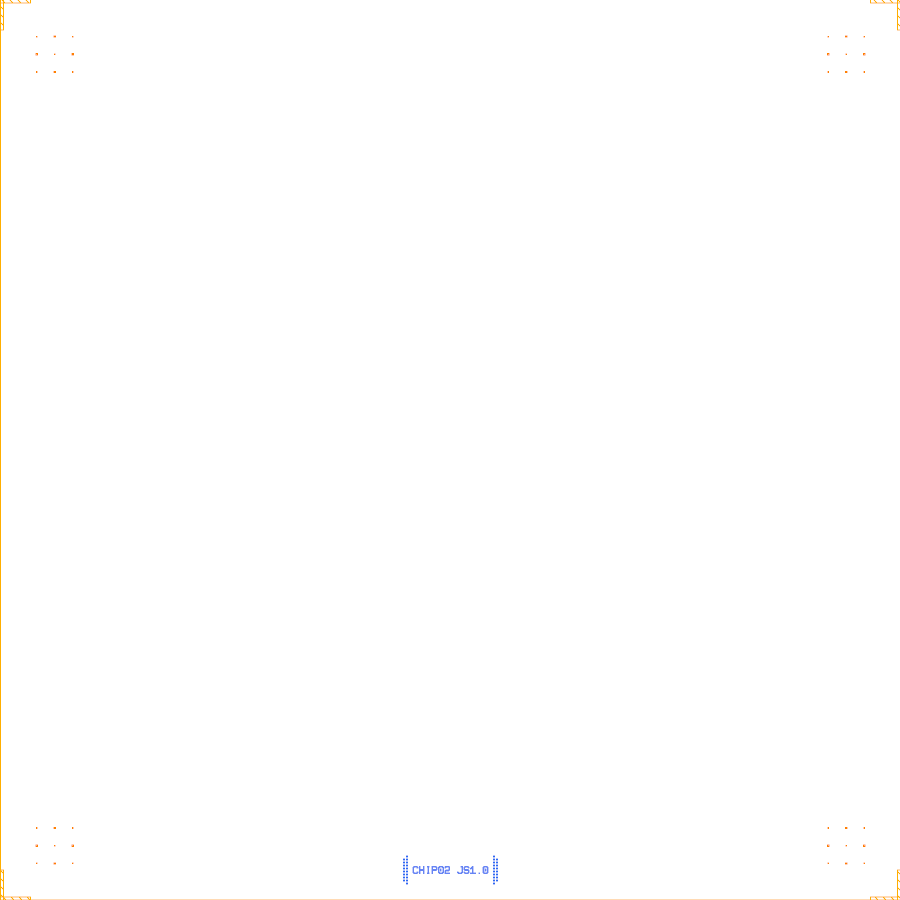

WindowsPath('build/legacy_steps/chip_02_1_frame.png')

In [5]:
d = Designer(ID, box=(0, 0, L.W, L.H), chip={"name_chip": f"CHIP02 JS{JS}"}, live=LIVE)   # cheese "auto"
print(d.design.chip.box, d.design.pdk)
L.step_snapshot(d, "1_frame")

## 4 · Pads (PDK pad rule) and the feedline

The rounded legacy "Connector Pad" (`ConnectorPad`: 275 × 300 µm pad, 300 µm taper, fab drawing) goes at the
left end of the feedline with the legacy rotation (rot 3). `edge="auto"` slides it perpendicular to its
nearest die edge until the outer edge of its etch is **`pad_edge` = 100 µm** from the die edge (read from
`get_pdk().frame.pad_edge`; the design-area margin). The legacy pads ended 245 µm *outside* the die (the chip
was laid out for a smaller die).

The feedline (`CpwSegment`, 10/6 µm) then snaps onto the left pad's port with the length the rule leaves on
this symmetric chip (die width − 2 × the port's x), and the right pad snaps onto its far end, as in the source
(pads snapped to the feedline ends). Snaps are real connections: pad, feedline and pad are one conductor in
the netlist (a plain `at=` feedline between two pads would not be connected). `L.edge_gaps` measures both
pads from the built etch. The feedline still spans all five couplers (legacy x = −2150 … +2150).

pad etch → die edge (µm): {'PL': 100.0, 'PR': 100.0} | rule: 100.0
feedline 5260 µm (legacy 5950 µm; pads 345 µm in from the legacy tips)


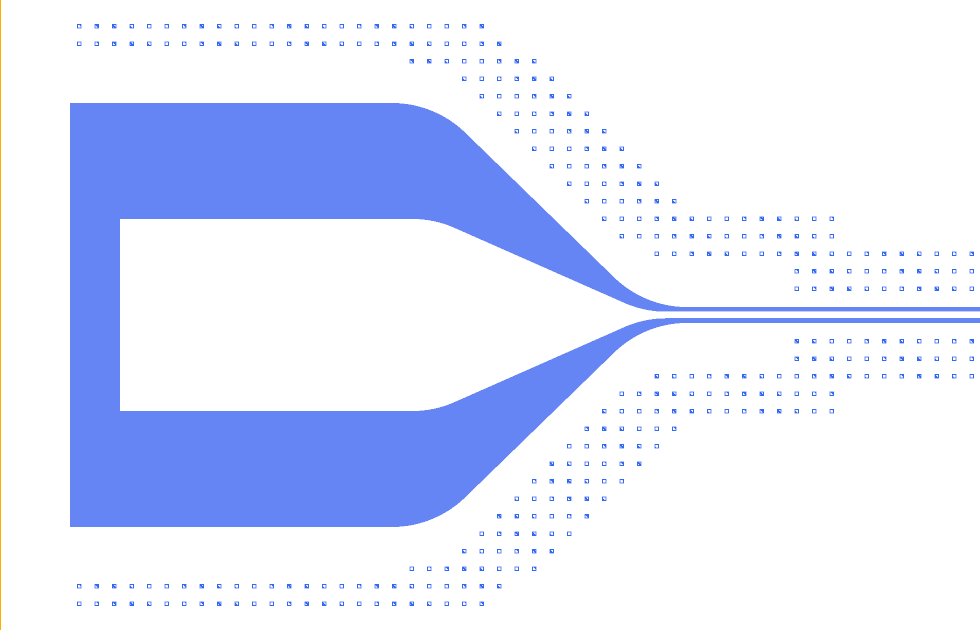

WindowsPath('build/legacy_steps/chip_02_2_pads.png')

In [6]:
d.add("PL", "ConnectorPad", **L.place(-2700, 0, 3), edge="auto", **L.connector_pad(**PAD))   # legacy (−2975, 0), rot 3
x_pad = L.W / 2 - C.port_xy(d, "PL.a")[0]          # feedline half-length the rule leaves (legacy frame)
PAD_SHIFT = round(FEED["length"] / 2 - x_pad, 3)    # pads moved in from the legacy tips
with d.batch():
    d.add("FL", "CpwSegment", snap="a", to="PL.a", **L.cpw_segment(**FEED | {"length": round(2 * x_pad, 3)}))
    d.add("PR", "ConnectorPad", snap="a", to="FL.b", **L.connector_pad(**PAD))   # legacy (+2975, 0), rot 1
print("pad etch → die edge (µm):", L.edge_gaps(d), "| rule:", get_pdk().frame.pad_edge)
print(f"feedline {2 * x_pad:.0f} µm (legacy {FEED['length']} µm; pads {PAD_SHIFT:g} µm in from the legacy tips)")
L.step_snapshot(d, "2_pads", box=(0, 3300, 1400, 4200), size=(980, 630), width=490)

## 5 · Components: resonators, Xmons and their junctions

Each `CoupledResonator` is the legacy `Coupled Resonator` PCell: a meandered 10/6 µm λ/4 (`cpw_len`), shorted
to ground at the end of a 300 µm coupler that runs beside the feedline behind a 2 µm ground strip, and an
**uncapped** far end (`ground=False`, the PCell's "xmon connector" mode). Each `Xmon` (legacy `Xmon
Cross`, one claw) is **snapped with its claw-tail tip onto that end** (`snap="claw_n", to="Ri.end"`): the
claw is the resonator's open end, galvanically, so the qubit–resonator coupling is the claw capacitance. The
Xmon keeps its legacy x and rotation and only moves along the tail axis (table below).
`d.couple("K_Ri", "Ri", "FL")` declares the coupler ∥ feedline coupling, which no port carries; the netlist
turns it into a hanger κ element. Each qubit with a junction gets a FEM sim group (qubit + resonator).

**Junctions (PDK rule).** `junction_creator.py` (the legacy `JUNC` cell) is not in the library, so each
qubit draws the PDK **`Quantcore Junction`** (trilayer: fingers on 2/0 + 4/0, spacer 50/0 with the 51–53/0
gradient, CLEARER box). `L.nominal` declares the legacy nominal junction (the AVA test-pad fingers at JS 1.0,
0.26 × 0.2 µm, assumed for the qubits too), which the PDK rule sizes to **R_n = 45 kΩ**.

| pair | legacy Xmon centre (legacy frame) | corrected Xmon centre | moved by (µm) | gap claw tip ↔ tail end |
|---|---|---|---|---|
| Q1/R1 | (-2000, 2270) | (-2000.0, 2105.9) | Δx +0.0, Δy -164.1 | -0.000 µm |
| Q2/R2 | (-1000, -2100) | (-1000.0, -2314.9) | Δx +0.0, Δy -214.9 | 0.000 µm |
| Q3/R3 | (0, 1910) | (0.0, 2124.9) | Δx +0.0, Δy +214.9 | -0.000 µm |
| Q4/R4 | (1000, -1990) | (1000.0, -1794.9) | Δx +0.0, Δy +195.1 | 0.000 µm |
| Q5/R5 | (2000, 1660) | (2000.0, 1873.9) | Δx +0.0, Δy +213.9 | -0.000 µm |

PDK junction rule: Nb trilayer, Δ = 1.4 meV → I_c·R_n = πΔ/2e = 2.199 mV; PDK process R_n·A = 13500 Ω·µm² (J_c = 0.163 µA/µm²; nominal 0.5 × 0.6 µm → 45 kΩ, L_J 6.73 nH), C_J = 50 fF/µm² (R_n·A and C_J assumed by the PDK). Qubit junctions: PDK cells sized by the rule, legacy nominal JS 1.0: 0.26 × 0.2 µm → R_n = 45 kΩ, other legacy sizes R_n ∝ 1/area.


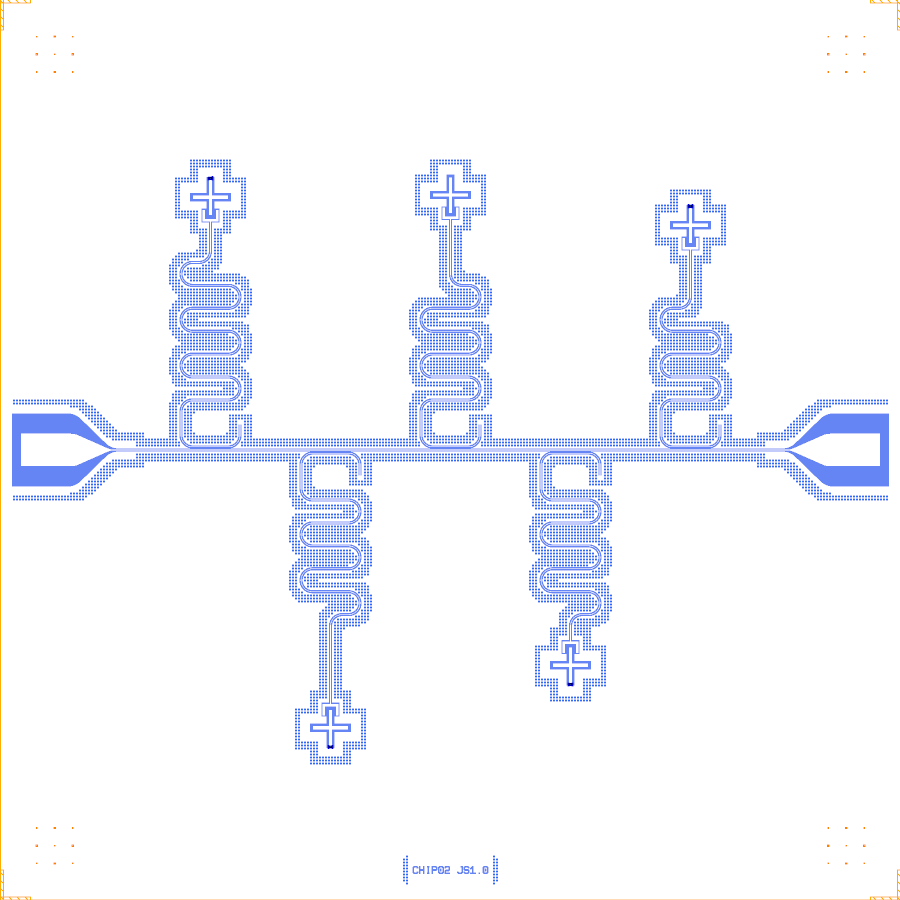

WindowsPath('build/legacy_steps/chip_02_3_components.png')

In [7]:
with d.batch():
    for i, (x, y_res, mirror, neck, length, y_q, rot, has_jj) in enumerate(QUBITS, 1):
        d.add(f"R{i}", "CoupledResonator", **L.place(x, y_res, 0, mirror),
              **L.coupled_resonator(**RES, neck_length=neck, cpw_len=length))
        # #8: claw-tail tip snapped onto the uncapped tail end (galvanic); legacy centre (x, y_q)
        d.add(f"Q{i}", "Xmon", snap="claw_n", to=f"R{i}.end", **L.xmon(**XMON),
              **(L.pdk_cell(*JJ_FINGERS, n=JJ_N) if has_jj else {"junction_type": "No Squid"}),
              junction=L.sized(*JJ_FINGERS, n=JJ_N) if has_jj else None)
        d.couple(f"K_R{i}", f"R{i}", "FL", note="300 µm coupler parallel to the feedline, 2 µm ground strip")
        if has_jj:                         # Q3 (no junction) has no port to excite: no FEM group
            d.sim_group(f"Q{i}R{i}", [f"Q{i}", f"R{i}"])
display(Markdown(L.claw_join_md(d, [(f"Q{i}", f"R{i}", (q[0], q[5])) for i, q in enumerate(QUBITS, 1)])))
print(L.rule_md())
L.step_snapshot(d, "3_components")

## 6 · Test pads, and centring

The source also places the nine AVA junction test pads (`JunctionTestPads`, legacy JS fingers) at their legacy positions. They have no ports (nothing in the netlist) and are not bond pads, so
the pad rule does not move them. No routes: like the legacy chip it is drawn from fixed cells whose ports
touch.

**Centring (PDK placement rule).** `L.center_circuit` measures the circuit (instances and routes) and shifts
the design so it sits in the middle of the die, on each axis only if it is more than 50 µm off (so a
symmetric legacy chip keeps its exact legacy coordinates). Then the design is saved: the JSON is what every
later step reads.

centring shift (µm): (0.0, 0.0) | feedline y = 3750.0 | <Designer chip_02: 22 instances, 0 routes, live=False> → examples\designs\legacy\chip_02.json


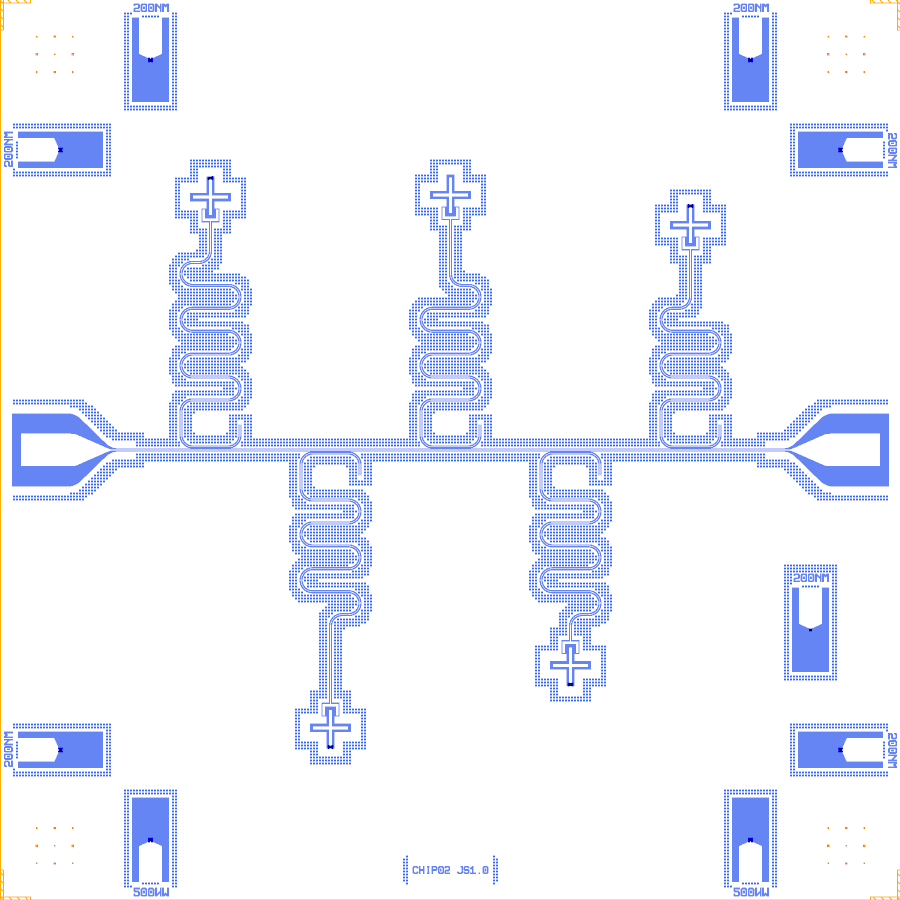

WindowsPath('build/legacy_steps/chip_02_4_centred.png')

In [8]:
with d.batch():
    for k, (x, y, rot, mirror) in enumerate(TESTPADS, 1):
        d.add(f"TP{k}", TEST_PAD[0], **L.place(x, y, rot, mirror), **TEST_PAD[1])
SHIFT = L.center_circuit(d)
DESIGN = d.save(OUT / f"{ID}.json")
print("centring shift (µm):", SHIFT, "| feedline y =", round(C.port_xy(d, "FL.a")[1], 1), "|", d, "→", DESIGN)
L.step_snapshot(d, "4_centred")

## 7 · DRC

`d.drc()` builds the chip and checks it: **errors** (overlapping etch of unrelated cells, ports not landing,
parts outside the chip) must be fixed; **warnings** are reported for a person to judge (a dangling open end,
two cells' bounding boxes touching); **PDK design warnings** (`pad_edge`, `pdk_rn`, `pdk_fq`, `pdk_claw`) flag
values outside the PDK margins — they are never retuned for, only listed. `C.pdk_report(d)` summarises the
PDK checks: cheese source, content centring, junction types and the design warnings.

Expected: zero errors; `frame_margin` warnings on TP2–TP9: the eight edge test pads (700 × 300 µm AVA windows at
(±2500, ±3250) and (±3250, ±2500), legacy positions kept) reach into the 100 µm die margin. They are test
structures, not bond pads, so the pad rule does not move them (design decision if they should move in). No PDK
design warnings; `pdk_report`: cheese "PDK band", content centre (+0, +0) µm.

In [9]:
drc = d.drc()
print(drc)
display(Markdown(C.pdk_report(d)))

warning frame_margin  TP2 reaches into the 100 µm die margin (dicing markers)
warning frame_margin  TP3 reaches into the 100 µm die margin (dicing markers)
warning frame_margin  TP4 reaches into the 100 µm die margin (dicing markers)
warning frame_margin  TP5 reaches into the 100 µm die margin (dicing markers)
warning frame_margin  TP6 reaches into the 100 µm die margin (dicing markers)
warning frame_margin  TP7 reaches into the 100 µm die margin (dicing markers)
warning frame_margin  TP8 reaches into the 100 µm die margin (dicing markers)
warning frame_margin  TP9 reaches into the 100 µm die margin (dicing markers)


| check | value |
|---|---|
| cheese | PDK band (drawn in the build) |
| content centre − die centre | (+0, +0) µm |
| junction types | Quantcore Junction × 4, No Squid × 1 |
| PDK design warnings | 0 (none) |

## 8 · Netlist and LOM

`d.lom()` turns the layout into a lumped-element circuit. Each Xmon → an island node (its C and the junction
to ground) plus a claw node (C_g to the island, C to ground). Each `CoupledResonator` → a λ/4 `TLres` from its
shorted coupler end to its open end `Ri.end`, which is the claw node (the Xmon is snapped onto it: one
conductor), and a `HANGER` κ element to the feedline (`K_Ri`). The feedline and both pads are one node with a
50 Ω port at each pad. The test pads have no ports.

In [10]:
lb = d.lom()
C.show_netlist(lb)
print(C.lom_summary(lb))

**12 nodes · 31 branches · 0 controls · 0 unconnected ports**

| node | FEM nets |
|---|---|
| `gnd` | ground |
| `FL.line` | `PL.pad`, `FL.line`, `PR.pad` |
| `R1.res` | `R1.res`, `Q1.claw_n` |
| `Q1` | `Q1.island` |
| `R2.res` | `R2.res`, `Q2.claw_n` |
| `Q2` | `Q2.island` |
| `R3.res` | `R3.res`, `Q3.claw_n` |
| `Q3` | `Q3.island` |
| `R4.res` | `R4.res`, `Q4.claw_n` |
| `Q4` | `Q4.island` |
| `R5.res` | `R5.res`, `Q5.claw_n` |
| `Q5` | `Q5.island` |

| branch | type | nodes | estimate |
|---|---|---|---|
| `Port_PL` | R | `FL.line` – `gnd` | 50 Ω |
| `Port_PR` | R | `FL.line` – `gnd` | 50 Ω |
| `C_Q1` | C | `Q1` – `gnd` | 64 fF |
| `J_Q1` | JJ | `Q1` – `gnd` | Lj 6.73 nH, Cj 15 fF |
| `Cg_Q1_claw_n` | C | `Q1` – `R1.res` | 3.17 fF |
| `Cc_Q1_claw_n` | C | `R1.res` – `gnd` | 76.4 fF |
| `C_Q2` | C | `Q2` – `gnd` | 64 fF |
| `J_Q2` | JJ | `Q2` – `gnd` | Lj 6.73 nH, Cj 15 fF |
| `Cg_Q2_claw_n` | C | `Q2` – `R2.res` | 3.17 fF |
| `Cc_Q2_claw_n` | C | `R2.res` – `gnd` | 76.4 fF |
| `C_Q3` | C | `Q3` – `gnd` | 64 fF |
| `Cg_Q3_claw_n` | C | `Q3` – `R3.res` | 3.17 fF |
| `Cc_Q3_claw_n` | C | `R3.res` – `gnd` | 76.4 fF |
| `C_Q4` | C | `Q4` – `gnd` | 64 fF |
| `J_Q4` | JJ | `Q4` – `gnd` | Lj 6.73 nH, Cj 15 fF |
| `Cg_Q4_claw_n` | C | `Q4` – `R4.res` | 3.17 fF |
| `Cc_Q4_claw_n` | C | `R4.res` – `gnd` | 76.4 fF |
| `C_Q5` | C | `Q5` – `gnd` | 64 fF |
| `J_Q5` | JJ | `Q5` – `gnd` | Lj 6.73 nH, Cj 15 fF |
| `Cg_Q5_claw_n` | C | `Q5` – `R5.res` | 3.17 fF |
| `Cc_Q5_claw_n` | C | `R5.res` – `gnd` | 76.4 fF |
| `R1` | TLres | `R1.res` – `gnd` | lambda/4, 5050 µm, 6.239 GHz |
| `K_R1` | HANGER | `R1.res` – `FL.line` | κ 0.337 MHz (L 300 µm) |
| `R2` | TLres | `R2.res` – `gnd` | lambda/4, 4850 µm, 6.497 GHz |
| `K_R2` | HANGER | `R2.res` – `FL.line` | κ 0.381 MHz (L 300 µm) |
| `R3` | TLres | `R3.res` – `gnd` | lambda/4, 4660 µm, 6.762 GHz |
| `K_R3` | HANGER | `R3.res` – `FL.line` | κ 0.429 MHz (L 300 µm) |
| `R4` | TLres | `R4.res` – `gnd` | lambda/4, 4330 µm, 7.277 GHz |
| `K_R4` | HANGER | `R4.res` – `FL.line` | κ 0.535 MHz (L 300 µm) |
| `R5` | TLres | `R5.res` – `gnd` | lambda/4, 4000 µm, 7.877 GHz |
| `K_R5` | HANGER | `R5.res` – `FL.line` | κ 0.678 MHz (L 300 µm) |

**Unconnected ports:** none

**Builder notes:**

- Q3: junction_type 'No Squid' → no junction element (island C only)

{'nodes': 11, 'branches': 31, 'controls': 0, 'unconnected': 0}


## 9 · LOM simulation

One sub-circuit per qubit / resonator pair with the feedline and both 50 Ω pads (`C.simulate_groups`: QuCat
normal modes → QuTiP-dressed f_q, α, f_r, κ, χ); the junction-less Q3 only loads R3 (group "R3+Q3 cross").
The values are component estimates (Xmon calibration, CPW λ/4, hanger κ) with the PDK junction rule; the
source states no targets. The junction tables give R_n, I_c, L_J and C_J of the qubits' PDK cells and of the
test pads' drawn legacy fingers (PDK process).

In [11]:
groups = {}
for i, q in enumerate(QUBITS, 1):                       # every claw is the open end of its resonator (#8)
    groups[f"Q{i}+R{i}" if q[7] else f"R{i}+Q{i} cross"] = [f"Q{i}", f"R{i}", "FL", "PL", "PR"]
results = C.simulate_groups(d, groups)
display(Markdown(C.groups_md(results)))
display(Markdown(L.sized_table([(f"Q{i} (JS {JS})", *JJ_FINGERS, JJ_N) for i, q in enumerate(QUBITS, 1) if q[7]])))
display(Markdown(L.junction_table([(f"test pads TP* (JS {JS})", *TEST_PAD_FINGERS, 1)])))

| group | qubit | f_q (GHz) | α (MHz) | resonator | f_r (GHz) | κ (MHz) | χ (MHz) |
|---|---|---|---|---|---|---|---|
| Q1+R1 | Q1 | 6.5224 | -255.8 | R1 | 5.6207 | 0.222 | -1.9 |
| Q2+R2 | Q2 | 6.5236 | -253.7 | R2 | 5.829 | 0.246 | -4.03 |
| R3+Q3 cross | – | – | – | R3 | 6.0473 | 0.275 | – |
| Q4+R4 | Q4 | 6.5539 | -358.8 | R4 | 6.4245 | 0.319 | 72.1 |
| Q5+R5 | Q5 | 6.5109 | -250.7 | R5 | 6.9399 | 0.37 | -6.96 |

PDK junction rule: Nb trilayer, Δ = 1.4 meV → I_c·R_n = πΔ/2e = 2.199 mV; PDK process R_n·A = 13500 Ω·µm² (J_c = 0.163 µA/µm²; nominal 0.5 × 0.6 µm → 45 kΩ, L_J 6.73 nH), C_J = 50 fF/µm² (R_n·A and C_J assumed by the PDK). Qubit junctions: PDK cells sized by the rule, legacy nominal JS 1.0: 0.26 × 0.2 µm → R_n = 45 kΩ, other legacy sizes R_n ∝ 1/area.

Qubit junctions (PDK cells, sized by the rule from the legacy nominal):

| junction | legacy fingers (µm) | n | R_n (kΩ) | I_c (nA) | L_J (nH) | drawn PDK fingers (µm) | C_J (fF) |
|---|---|---|---|---|---|---|---|
| Q1 (JS 1.0) | 0.26 × 0.2 | 1 | 45.00 | 48.9 | 6.734 | 0.5 × 0.6 | 15.00 |
| Q2 (JS 1.0) | 0.26 × 0.2 | 1 | 45.00 | 48.9 | 6.734 | 0.5 × 0.6 | 15.00 |
| Q4 (JS 1.0) | 0.26 × 0.2 | 1 | 45.00 | 48.9 | 6.734 | 0.5 × 0.6 | 15.00 |
| Q5 (JS 1.0) | 0.26 × 0.2 | 1 | 45.00 | 48.9 | 6.734 | 0.5 × 0.6 | 15.00 |

PDK junction rule: Nb trilayer, Δ = 1.4 meV → I_c·R_n = πΔ/2e = 2.199 mV; PDK process R_n·A = 13500 Ω·µm² (J_c = 0.163 µA/µm²; nominal 0.5 × 0.6 µm → 45 kΩ, L_J 6.73 nH), C_J = 50 fF/µm² (R_n·A and C_J assumed by the PDK). Qubit junctions: PDK cells sized by the rule, legacy nominal JS 1.0: 0.26 × 0.2 µm → R_n = 45 kΩ, other legacy sizes R_n ∝ 1/area.

Drawn junctions (legacy fingers) on the PDK process:

| junction | fingers (µm) | n | area (µm²) | R_n (kΩ) | I_c (nA) | L_J (nH) | C_J (fF) |
|---|---|---|---|---|---|---|---|
| test pads TP* (JS 1.0) | 0.26 × 0.2 | 1 | 0.0520 | 259.62 | 8.5 | 38.852 | 2.60 |

**Reading the numbers** (LOM of this run). The resonator-length sweep (5050 … 4000 µm) runs from 5.62 to 6.94 GHz
loaded, while every qubit sits at ≈ 6.52 GHz with the PDK rule: **Q4/R4 (6.55 / 6.42 GHz) are hybridised** (χ
72 MHz is not a dispersive shift); Q2/R2 and Q5/R5 are ≈ 0.4–0.7 GHz apart. Detuning Q4 (R_n at one end of the
40–50 kΩ window, or retuned lengths) is a design decision.

## 10 · FEM: send the job

Each sim group is cut out of the chip (its instances plus a margin of ground), with the PDK stack (sapphire
650 µm, ε_r 10.25) and **without cheese** (simulation exports never have it), and written as a job folder
under `build/jobs/` (`C.export_sims` → `build_simulation` + `export_job`): a Q3D C-matrix job by default,
`analysis="eigenmode_epr"` for the eigenmode / EPR job. With `RUN_FEM = True` and AEDT 2024 R1 (v241) or
newer on this machine, `L.fem_send` solves each job in a **new batch, non-graphical** AEDT
(`sim_tools.hfss.solve_job`) — it never touches an AEDT window you have open. The default here is
`False`: export only.

Here: one Q3D C-matrix job per qubit + resonator group (cut out with a 300 µm margin; the nets are the Xmon
island and the claw + resonator conductor). Q3/R3 has no group: the junction-less reference Xmon gives the
job no port to excite.

In [12]:
RUN_FEM = False                       # True: solve the exported jobs here (AEDT 2024 R1+, batch)
jobs = C.export_sims(DESIGN)
display(Markdown(C.jobs_md(jobs)))
display(Markdown(L.fem_send(jobs, run=RUN_FEM)))

| group | job | ports (number · kind · name) | C-matrix nets |
|---|---|---|---|
| Q1R1 | `build/jobs/chip_02_Q1R1_q3d_cmatrix` | 1 · junction · `Q1.junction` | `Q1.island` |
| Q2R2 | `build/jobs/chip_02_Q2R2_q3d_cmatrix` | 1 · junction · `Q2.junction` | `Q2.island` |
| Q4R4 | `build/jobs/chip_02_Q4R4_q3d_cmatrix` | 1 · junction · `Q4.junction` | `Q4.island` |
| Q5R5 | `build/jobs/chip_02_Q5R5_q3d_cmatrix` | 1 · junction · `Q5.junction` | `Q5.island` |

AEDT on this machine: `C:\Program Files\AnsysEM\v241\Win64\ansysedt.exe` (v241)

`RUN_FEM = False`: 4 job(s) exported, none solved. Set `RUN_FEM = True` to solve them here (batch, non-graphical), or run `qcc sim run <job>` on a machine with AEDT 2024 R1+.

## 11 · Bring the results back

A solved job leaves `results/results.json` in its folder. `fill(model, DESIGN, job)` then replaces the LOM's
component estimates by the FEM C-matrix, matched by net name (the net names are the ones in the job table
above), and the LOM is simulated again with them. `L.fem_bring_back` does this for every job that has
results and says which have none yet.

No job has been solved yet (no `results.json` under `build/jobs/<id>_*`), so the cell says so. With results,
the C-matrix would replace the Xmon's island and claw capacitances and move f_q, α and χ.

In [13]:
display(Markdown(L.fem_bring_back(d, DESIGN, jobs, groups=None)))

No FEM results yet for 4 job(s) (`build/jobs/chip_02_Q1R1_q3d_cmatrix`, `build/jobs/chip_02_Q2R2_q3d_cmatrix`, `build/jobs/chip_02_Q4R4_q3d_cmatrix`, `build/jobs/chip_02_Q5R5_q3d_cmatrix`). After a solve each job holds `results/results.json`; this cell then fills the LOM with the extracted C-matrix (`fill(model, DESIGN, job)`) and shows the estimate next to the FEM value per capacitance, and f_q / α / f_r / χ re-simulated with them.

## 12 · Iterate: change one property and re-simulate

The design is data, so a variant is a copy with one parameter changed. Here Q1's junction is re-sized from
the nominal R_n = 45 kΩ to the low end of the PDK window, **40 kΩ** (`L.lj_for_rn(40e3)`: the L_J and C_J of
a PDK-drawn junction of that R_n; for a SQUID the parallel total): L_J falls by 11 %, so f_q rises by about
6 % and the qubit moves towards its resonator. The copy is not saved; the chip stays as built.

In [14]:
d2 = Designer.load(DESIGN, live=False, verbose=False)      # a copy of the saved design
J40 = L.lj_for_rn(40e3, n=JJ_N)
d2["Q1"].set(junction=J40, junction_params={"lj_nH": J40["Lj_nH"]})
after = C.simulate_groups(d2, {"Q1+R1": groups["Q1+R1"]})["Q1+R1"]
print("Q1 junction:", L.sized(*JJ_FINGERS, n=JJ_N), "→", J40)
display(Markdown(L.compare_md(results["Q1+R1"], after,
                              keys=["Q1.f_q_GHz", "Q1.alpha_MHz", "R1.f_GHz", "R1.chi_MHz"],
                              label=("R_n 45 kΩ", "R_n 40 kΩ"))))

Q1 junction: {'Lj_nH': 6.7344, 'Cj_fF': 15.0} → {'Lj_nH': 5.9862, 'Cj_fF': 16.875}


| parameter | R_n 45 kΩ | R_n 40 kΩ | Δ |
|---|---|---|---|
| `Q1.f_q_GHz` | 6.5224 | 6.8577 | +0.3353 |
| `Q1.alpha_MHz` | -255.81 | -249.37 | +6.436 |
| `R1.f_GHz` | 5.6207 | 5.6214 | +0.0006823 |
| `R1.chi_MHz` | -1.9011 | -0.85793 | +1.043 |

## 13 · Build and export

The design is saved as JSON (`DESIGN`, step 6): it is the source of truth — the layout, the netlist, the
FEM jobs and the mask are all made from it. The **fab mask** (`export_fab`) keeps only the PDK fab layers
(1/0 etch, 2/0 + 4/0 junction fingers, 3/0 second-metal keep-out, 50–53/0 spacer, 100/0 boundary, 1000/0 +
1001/0 markers), rounds the corners (radius ∝ each polygon's shortest dimension) and keeps the build's
cheese. **Simulation exports** never carry cheese; they drop airbridges unless asked
(`build_simulation(..., airbridges=True)`); the legacy chips have none.

Here: `cheese=True` (the default): the build already carries the PDK band (the source has no cheese), so the
mask keeps it (`cheese_source` "build").

The same from a shell:

```
qcc build examples/designs/legacy/chip_02.json                    # layout → build/chip_02.oas
qcc mask  examples/designs/legacy/chip_02.json          # fab mask with the PDK rules
qcc sim build examples/designs/legacy/chip_02.json -g Q1R1 -a q3d_cmatrix   # one FEM job (step 10)
qcc sim run build/jobs/chip_02_Q1R1_q3d_cmatrix              # solve it (AEDT 2024 R1+)
```

In [15]:
display(Markdown(L.fab_md(d, cheese=True)))

Fab mask: `build/chip_02_fab.oas` · cheese source **build** (9299 PDK-band holes) · corner rounding on

| fab layer | PDK name | polygons |
|---|---|---|
| 1/0 | M1 | 9395 |
| 2/0 | JJ_STRAIGHT | 13 |
| 3/0 | M3 | 9324 |
| 4/0 | JJ_BENT | 13 |
| 50/0 | HSQ | 8 |
| 51/0 | SPACER_1 | 8 |
| 52/0 | SPACER_2 | 8 |
| 53/0 | SPACER_3 | 8 |
| 100/0 | CHIP_BOUNDARY | 1 |
| 1000/0 | MARKERS_DICING | 4 |
| 1001/0 | MARKERS_ALIGN | 36 |

## 14 · Snapshots and comparison with the legacy geometry

The full chip, then Q1 with its claw joined to R1's tail end, Q1's junction (the PDK cell, with the cheese
band around the 3/0 keep-out) and R1's coupler on the feedline. Then the same chip drawn by the author's
legacy PCells and scripts (run read-only through `tests/legacy_ref`; junctions omitted because `junction_creator.py` is missing; legacy CLEARER cuts),
**with the pads and feedline at their PDK position** and the Xmons at the corrected (#8) positions, moved by
the centring shift, and the etch XOR per legacy instance against the rebuild (`1t1_base_metal_gap_wo_grid −
base_metal_addition`, i.e. PDK M1; slivers ≤ 2 nm ignored). Expected XOR: 0 on the resonators, test pads,
pads and feedline; the Xmons differ only by the junction windows (legacy CLEARER 30 × CUT_H µm vs the PDK
cell's own box). The rebuild's cheese is on its own layer (`ground_grid`), not part of the 1/0 compared.

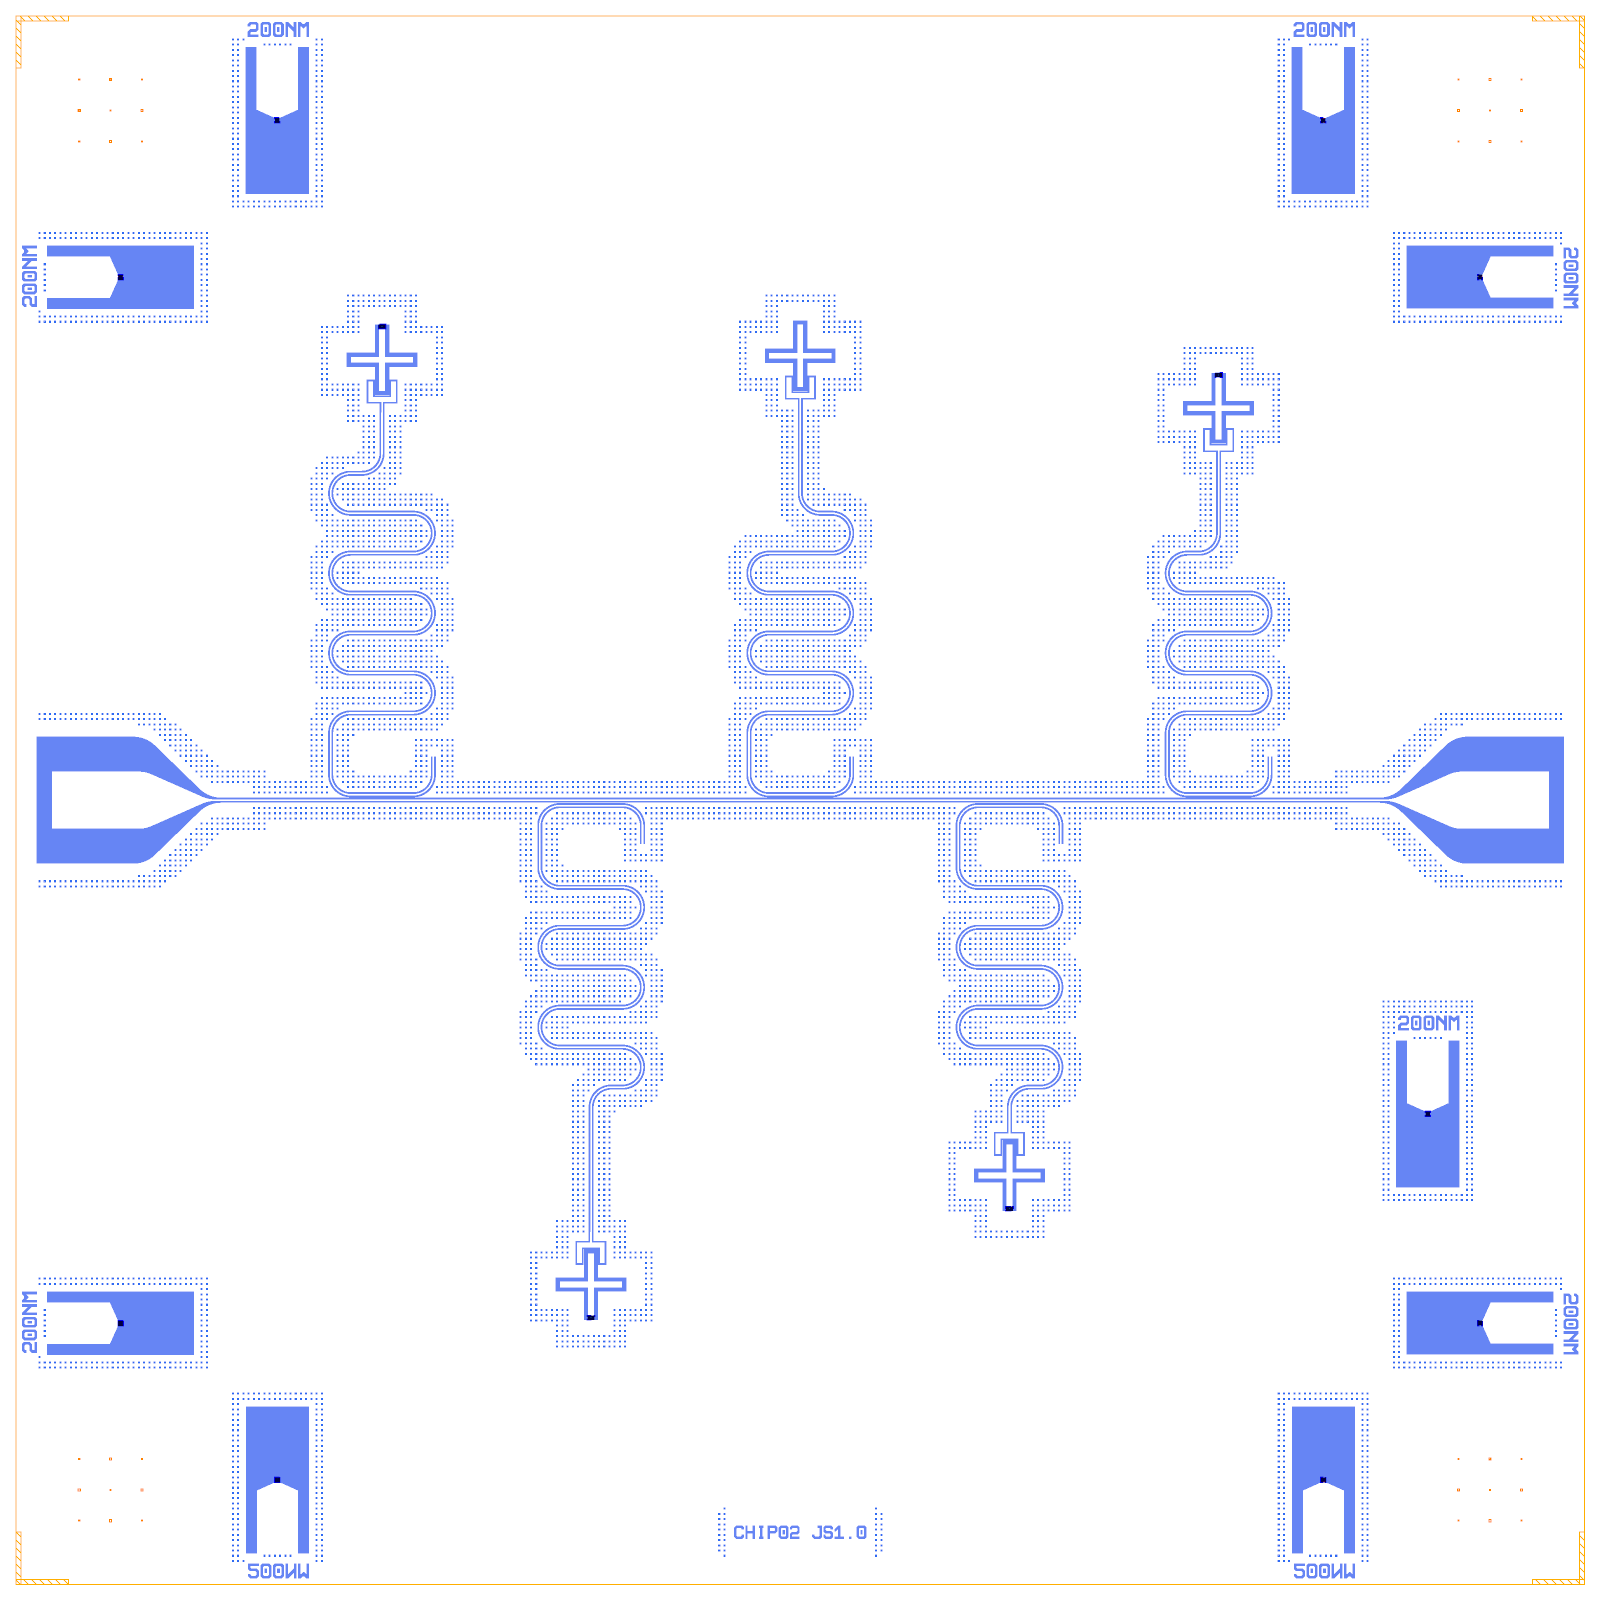

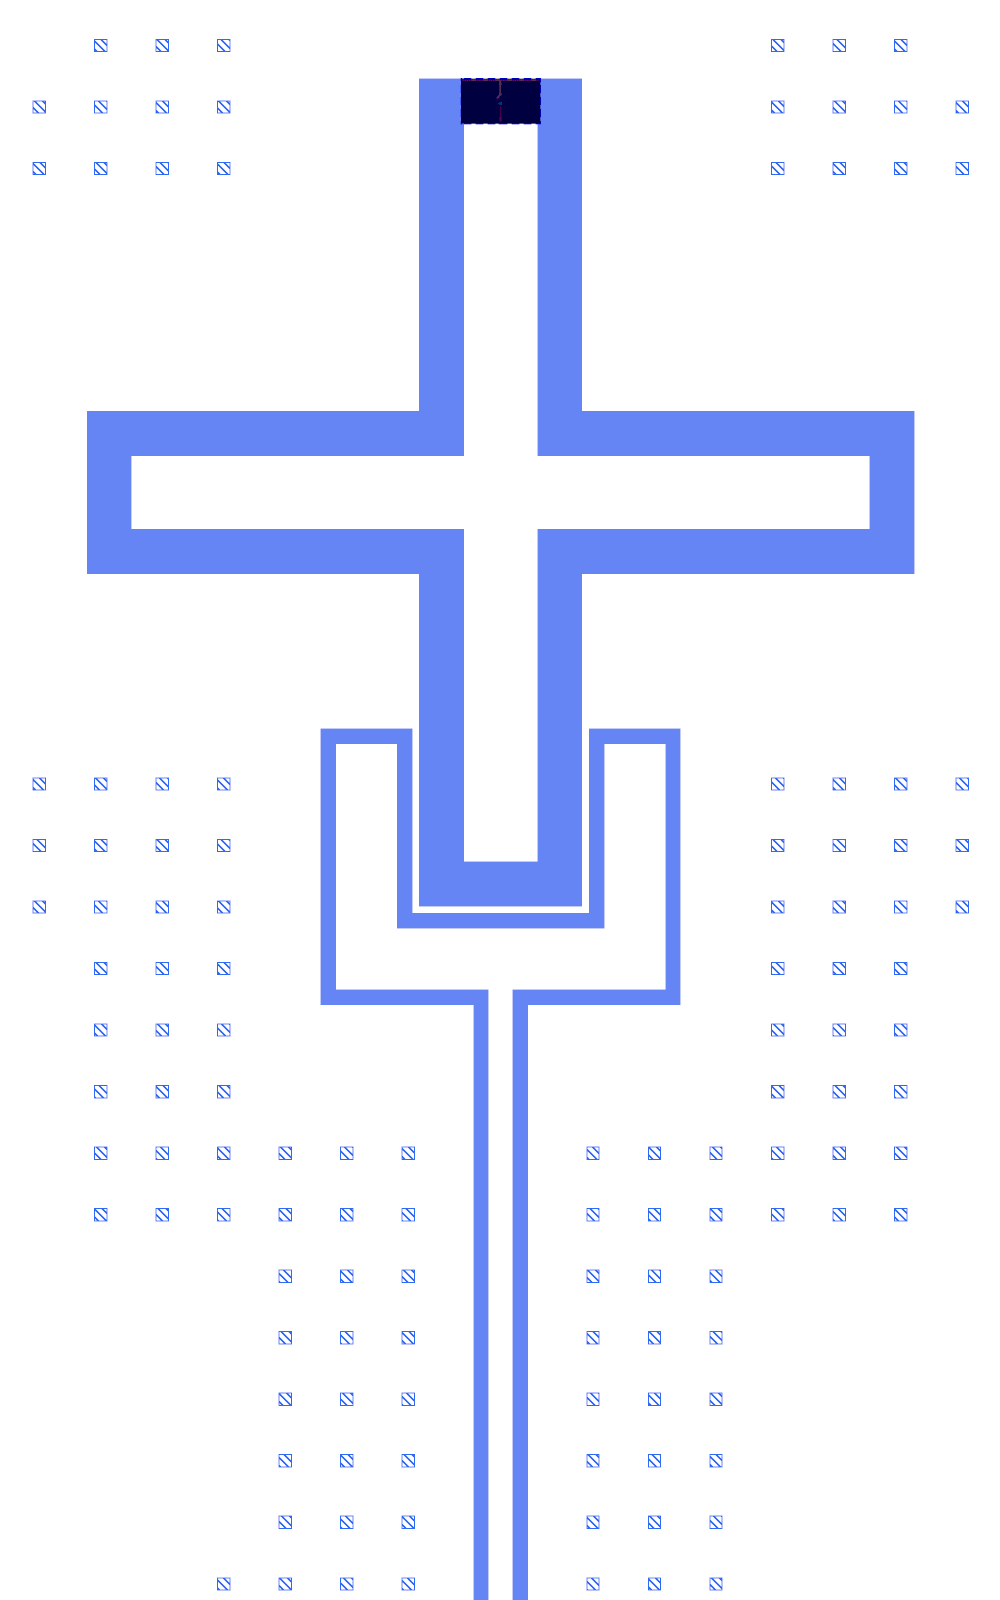

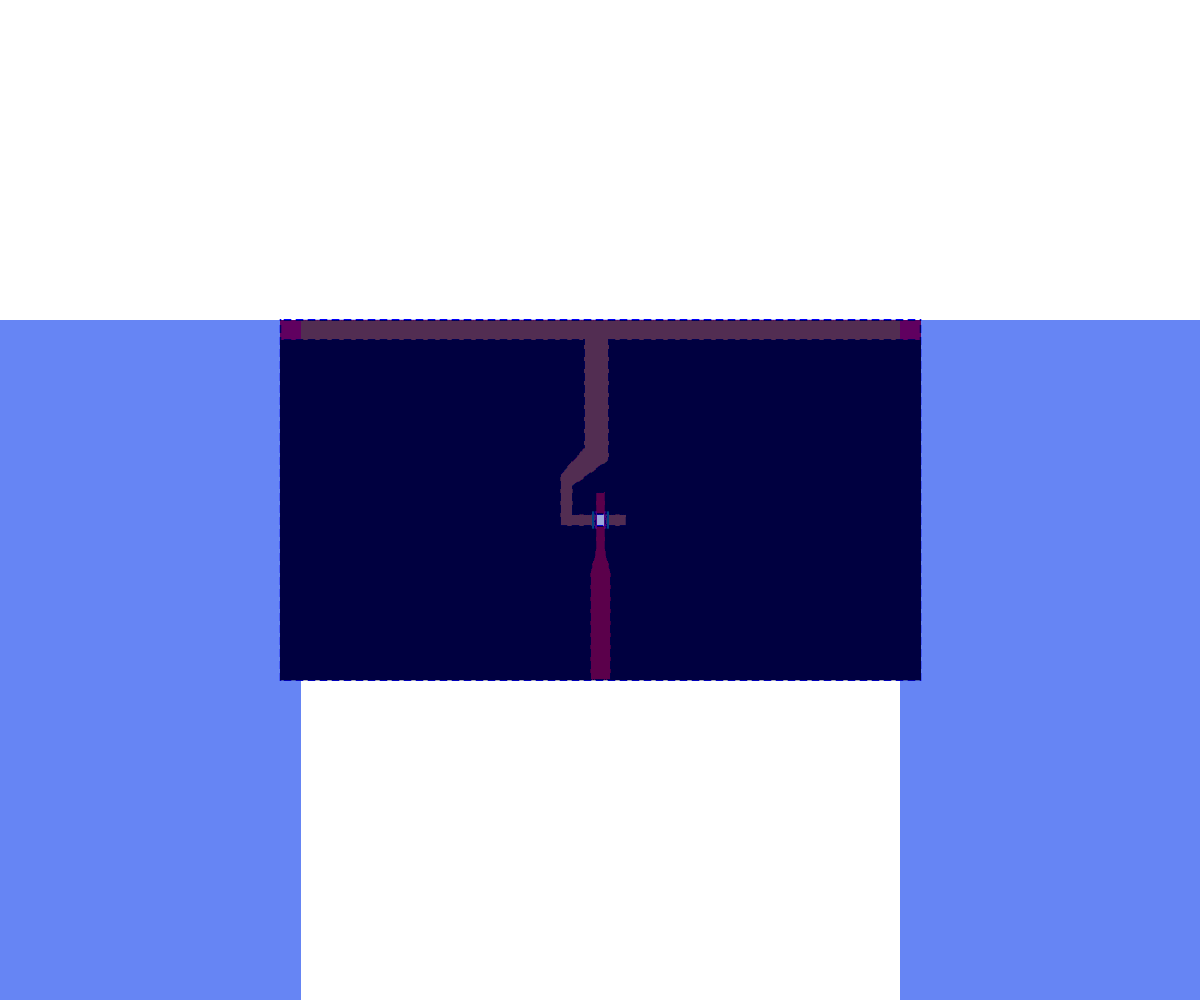

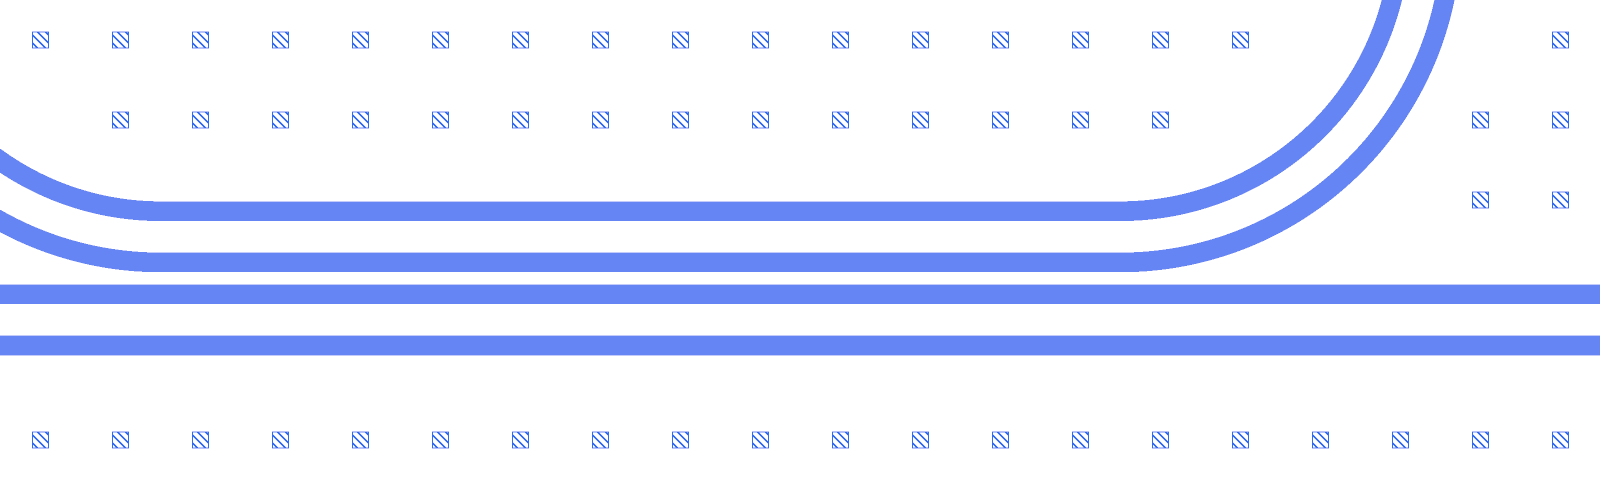

WindowsPath('examples/designs/legacy/chip_02_coupler.png')

In [16]:
X1, Y1 = L.origin(d, "Q1")              # Q1 centre (Designer frame, snapped); junction 159 µm above it
XC = C.port_xy(d, "FL.a")[1]            # feedline y after centring
C.show_snapshot(d, OUT / f"{ID}.png")
C.show_snapshot(d, OUT / f"{ID}_q1.png", box=(X1 - 200, Y1 - 450, X1 + 200, Y1 + 200), size=(1000, 1600), width=400)
C.show_snapshot(d, OUT / f"{ID}_jj.png", box=(X1 - 30, Y1 + 134, X1 + 30, Y1 + 184), size=(1200, 1000), width=400)
C.show_snapshot(d, OUT / f"{ID}_coupler.png", box=(X1 - 200, XC - 50, X1 + 300, XC + 100), size=(1600, 480))

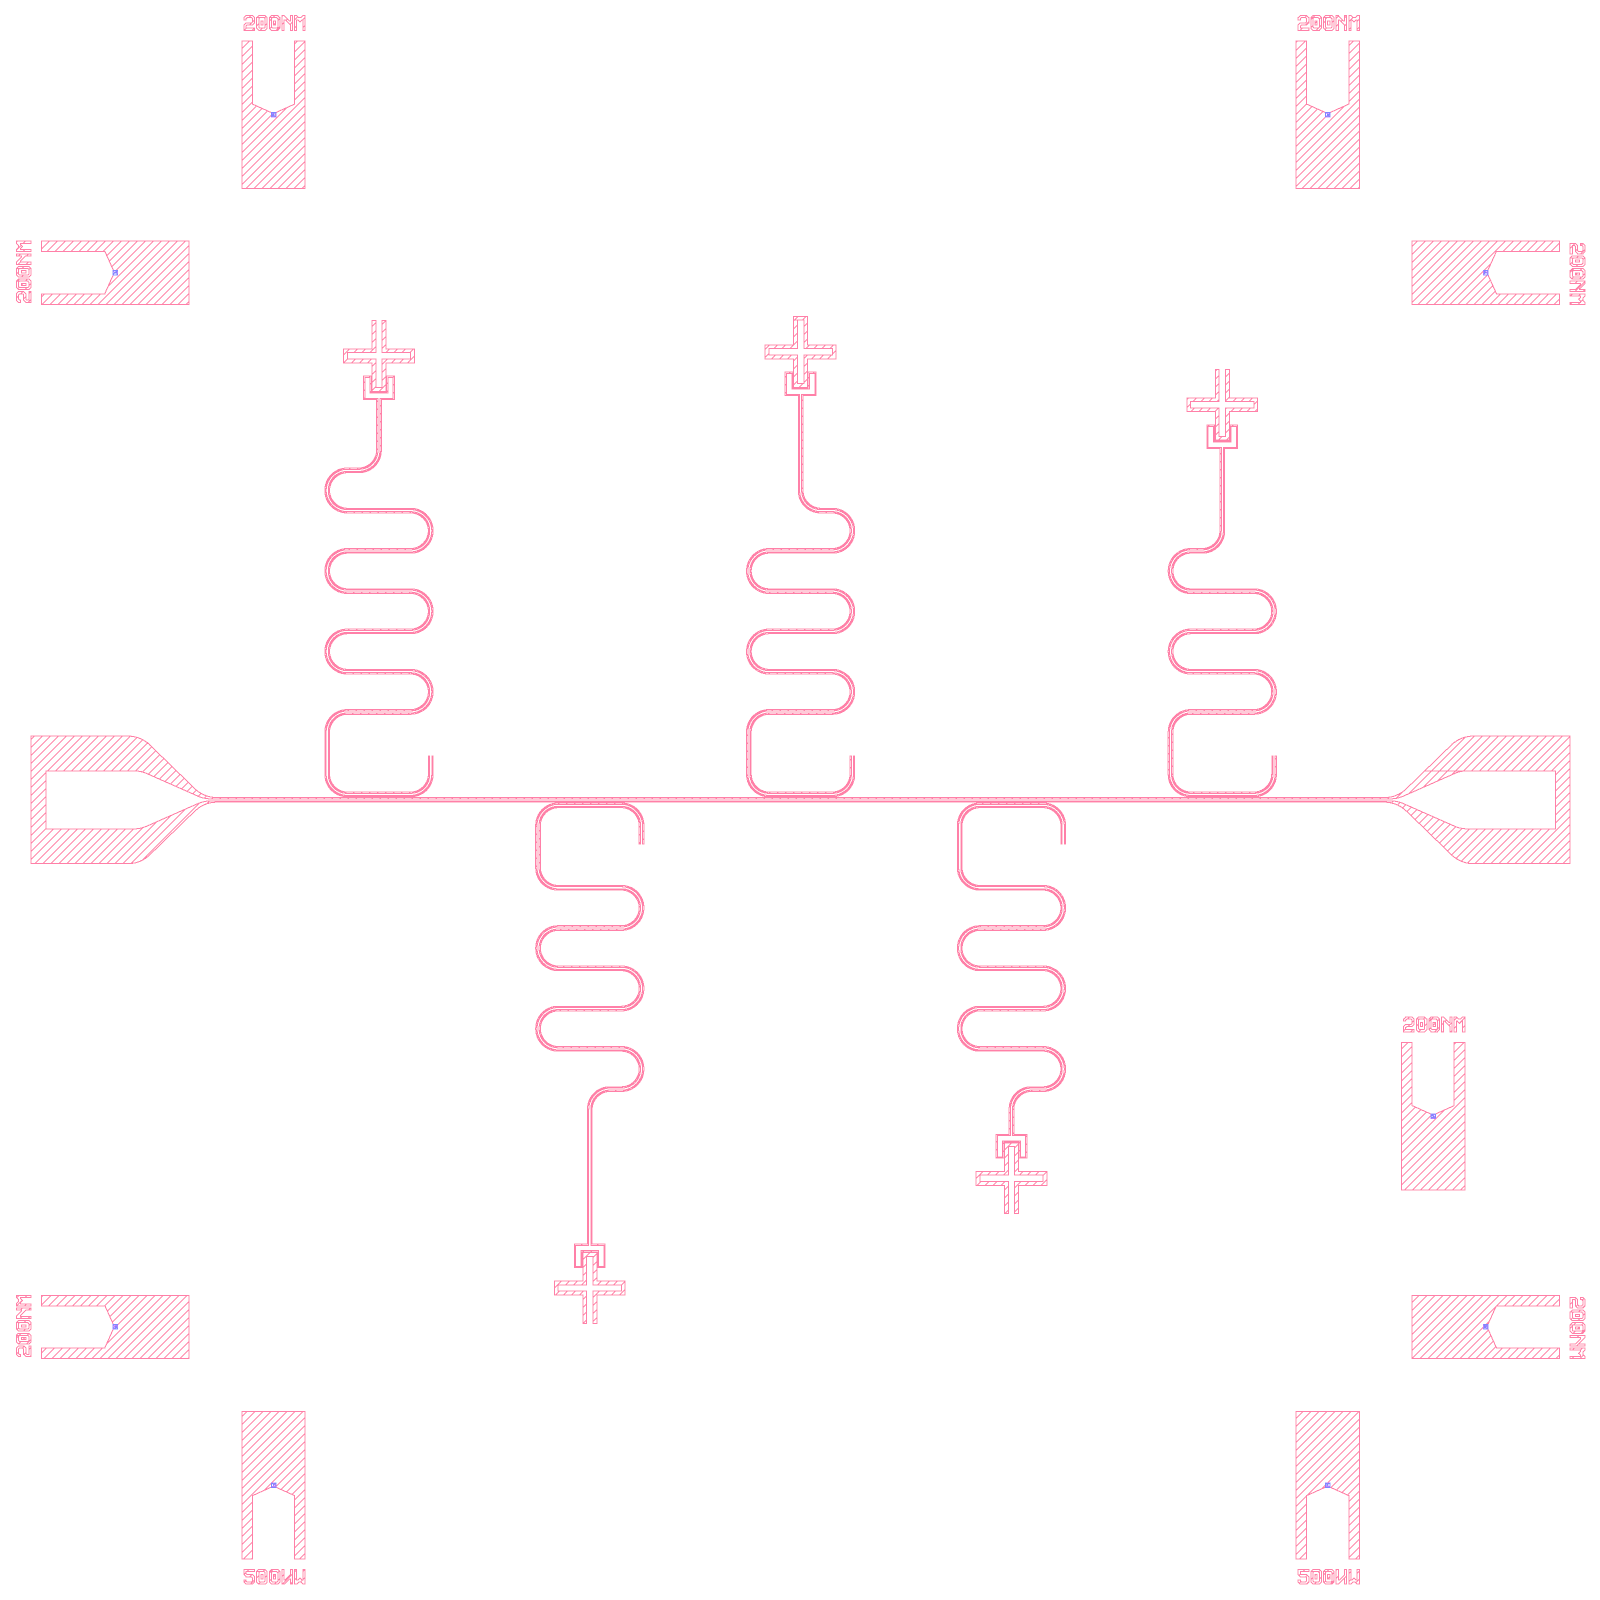

| instance | legacy etch (µm²) | rebuilt etch (µm²) | XOR (µm²) | XOR / legacy |
|---|---|---|---|---|
| FL | 63120 | 63120 | 0.0 | 0.00% |
| P1 | 244550 | 244550 | 0.0 | 0.00% |
| P2 | 244550 | 244550 | 0.0 | 0.00% |
| R1 | 60443 | 60443 | 0.0 | 0.00% |
| R2 | 58044 | 58044 | 0.0 | 0.00% |
| R3 | 55764 | 55764 | 0.0 | 0.00% |
| R4 | 51804 | 51804 | 0.0 | 0.00% |
| R5 | 47844 | 47844 | 0.0 | 0.00% |
| Q1 | 26676 | 26676 | 0.0 | 0.00% |
| Q2 | 26676 | 26676 | 0.0 | 0.00% |
| Q3 | 27216 | 27216 | 0.0 | 0.00% |
| Q4 | 26676 | 26676 | 0.0 | 0.00% |
| Q5 | 26676 | 26676 | 0.0 | 0.00% |
| TP1 | 154880 | 154880 | 0.0 | 0.00% |
| TP2 | 154880 | 154880 | 0.0 | 0.00% |
| TP3 | 154880 | 154880 | 0.0 | 0.00% |
| TP4 | 154880 | 154880 | 0.0 | 0.00% |
| TP5 | 154880 | 154880 | 0.0 | 0.00% |
| TP6 | 154880 | 154880 | 0.0 | 0.00% |
| TP7 | 154880 | 154880 | 0.0 | 0.00% |
| TP8 | 154880 | 154880 | 0.0 | 0.00% |
| TP9 | 154880 | 154880 | 0.0 | 0.00% |

max XOR without the Xmons (junction windows): 0.0 µm²


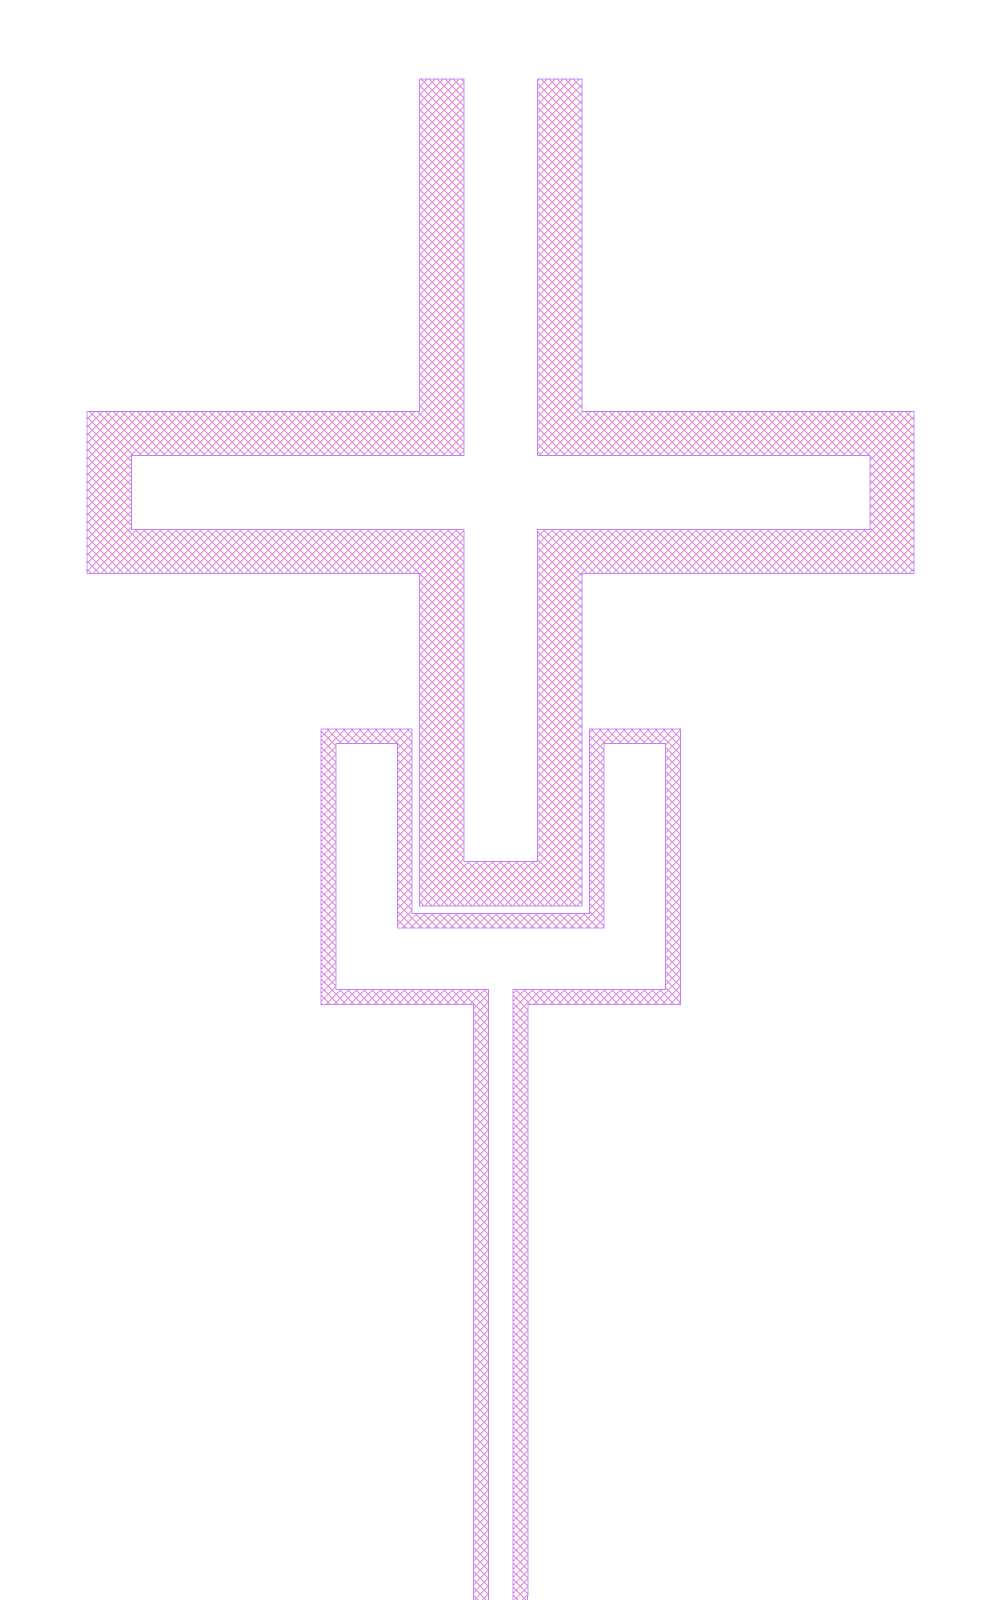

In [17]:
if L.legacy_available():
    from quantcore_circuits.live.snapshot import snapshot
    tp_cell = L.legacy_script_cell(*LEGACY_TP[:2], LEGACY_TP[2], *LEGACY_TP[3:], tmp=f"build/legacy_a/{ID}_tp")
    YQ = [L.origin(d, f"Q{i}")[1] - L.H / 2 - SHIFT[1] for i in range(1, len(QUBITS) + 1)]  # corrected (#8), legacy frame
    jy = lambda i: YQ[i] + (159 if YQ[i] > 0 else -159)   # junction centre, legacy frame
    ref = L.xmon_feedline_reference(
        ID, feed=FEED | {"length": 2 * x_pad},             # pads and feedline at the PDK pad position
        pads=[(PAD | {"sim": False}, -x_pad, 0, 3), (PAD | {"sim": False}, x_pad, 0, 1)],
        resonators=[(f"R{i}", RES | {"neck_length": q[3], "cpw_len": q[4]}, q[0], q[1], 0, q[2])
                    for i, q in enumerate(QUBITS, 1)],
        xmons=[(f"Q{i}", XMON, q[0], YQ[i - 1], q[6], False) for i, q in enumerate(QUBITS, 1)],
        testpads=[(f"TP{k}", tp_cell, x, y, rot, mirror) for k, (x, y, rot, mirror) in enumerate(TESTPADS, 1)],
        cutters=[(q[0] - 15, jy(i) - CUT_H / 2, q[0] + 15, jy(i) + CUT_H / 2) for i, q in enumerate(QUBITS) if q[7]])
    ref = L.shift_reference(ref, *SHIFT)
    snapshot(ref.write(f"build/legacy_a/{ID}_legacy.oas"), OUT / f"{ID}_legacy.png")
    display(Image(filename=str(OUT / f"{ID}_legacy.png"), width=640))
    table, xor = L.xor_table(d, ref)
    display(Markdown(table))
    print("max XOR without the Xmons (junction windows):",
          round(max(v for k, v in xor.items() if not k.startswith("Q")), 3), "µm²")
    L.xor_png(d, ref, OUT / f"{ID}_xor_q1.png", box=(X1 - 200, Y1 - 450, X1 + 200, Y1 + 200), size=(1000, 1600))
    display(Image(filename=str(OUT / f"{ID}_xor_q1.png"), width=400))
else:
    print("components/ (legacy library) not present: no legacy reference")

## 15 · Summary

- **Matches the source:** the resonators, Xmon crosses and claws, test pads, and the pads + feedline at their PDK
  position (XOR 0 µm² on everything except the Xmons' junction windows).
- **Differs, by the PDK:** pads `pad_edge` = 100 µm from the die edge (feedline 5260 µm, the position an earlier decision had
  chosen), the PDK frame and device ID, the PDK cheese band (fab: cheese source "build"), PDK trilayer junction
  cells sized to 45 kΩ.
- **Centring:** already centred (shift (0, 0)).
- **Open:** Q4/R4 collide (6.55 / 6.42 GHz); TP2–TP9 sit in the die margin; no PDK design warnings.